# Model Transfer (Data)


<b> Objective: </b>

Test if the model transfer knowledge between regions. Testing region is 20% of Pierpaolo's data. Training regions differ between setups:

1. Pierpaolo's 80%
2. Pierpaolo's 80% + Whole Rock 100%
3. Whole Rock 100%

(1) is the baseline; (2) tests if extra knowledge from a separate region helps; (3) tests if only that extra knowledge is up-to-par.

----------------------

<i><b>Author: </b> Salvador Palma <br>
<b>Institution: </b> Copenhagen University </i>

In [8]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import sys
import os
COLAB_SESSION = False

DRIVE_PATH = ""
if COLAB_SESSION:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DRIVE_PATH = "/content/drive/MyDrive/UCPH/POOCS/"
    sys.path.insert(0, DRIVE_PATH)
    
import pandas as pd
from GreenlandUtils import *
import openpyxl

## Setup

### Pierpaolo Excel to treated CSV

Same treatment as `1. Data Fetching.ipynb`

In [11]:
DATA_PATH = "Data/Pierpaolo/"
SOURCE_XLSX = "Data/Pierpaolo/greenland_portal.xlsx"

CACHE_DATA = f"{DRIVE_PATH}{DATA_PATH}Data.csv"

def Treat(raw: pd.DataFrame) -> pd.DataFrame:
    elementCols = [c for c in raw.columns if str(c).endswith(("ppm", "ppb", "wt%"))]
    df = raw.copy()

    for col in elementCols:
        values = df[col].astype(float)
        zero = values <= 0
      
        values[zero] = np.nan
        df[col] = values

    df = df.groupby("Sampleno", as_index=False).agg(
        { **{ c: "first" for c in ["Longitude", "Latitude", "Batch"] }, **{ c: "median" for c in elementCols } })
    df[elementCols] = np.log10(df[elementCols].where(df[elementCols] > 0))

    return df


if not os.path.exists(CACHE_DATA):
    raw = pd.read_excel(f"{DRIVE_PATH}{SOURCE_XLSX}")
    df = Treat(raw)
    df.to_csv(CACHE_DATA, sep=";", index=False)
    print(f"Treated {len(raw)} rows")

### Matching Datasets

Reads both `Whole Rock` and `Pierpaolo`'s version of Whole Rock, limits to common columns and adds the ratios of interest.

In [12]:
WHOLE_DATA_PATH = "Data/Whole Rock/Mean Merge/Data.csv"
PIERPAOLO_DATA_PATH = "Data/Pierpaolo/Data.csv"

whole_df = pd.read_csv(f"{DRIVE_PATH}{WHOLE_DATA_PATH}", delimiter=";")
pierpaolo_df = pd.read_csv(f"{DRIVE_PATH}{PIERPAOLO_DATA_PATH}", delimiter=";")

printable = Printable()

printable.title("Data Summary")
printable.add("Whole Rock", f"{whole_df.shape[0]} samples, {whole_df.shape[1]} features")
printable.add("Pierpaolo", f"{pierpaolo_df.shape[0]} samples, {pierpaolo_df.shape[1]} features")
printable.rest()

printable.add("Columns not in Pierpaolo", f"{len(set(whole_df.columns) - set(pierpaolo_df.columns))}")
printable.add("Columns not in Whole Rock", f"{len(set(pierpaolo_df.columns) - set(whole_df.columns))}")
printable.add("Columns in both", f"{len(set(whole_df.columns) & set(pierpaolo_df.columns))}")
printable.rest()

ELEMENTS = ["Cu", "Pb", "Zn", "Mo", "W", "Sb", "Ba", "Sr"]
RATIOS = [("Cu", "Pb"), ("Cu", "Zn"), ("Mo", "Pb"), ("Mo", "Sb"), ("W", "Pb"), ("W", "Sb"), ("Ba", "Sr")]

printable.add("Elements of interest", f"{ELEMENTS}")
printable.add("Elements missing in Whole Rock", f"{len(set([f"{e} ppm" for e in ELEMENTS]) - set(whole_df.columns))}")
printable.add("Elements missing in Pierpaolo", f"{len(set([f"{e} ppm" for e in ELEMENTS]) - set(pierpaolo_df.columns))}")

printable.flush()

============================== Data Summary ==============================
Whole Rock:                       6957 samples, 91 features
Pierpaolo:                        4000 samples, 70 features


Columns not in Pierpaolo:         30
Columns not in Whole Rock:        9
Columns in both:                  61


Elements of interest:             ['Cu', 'Pb', 'Zn', 'Mo', 'W', 'Sb', 'Ba', 'Sr']
Elements missing in Whole Rock:   0
Elements missing in Pierpaolo:    0


In [13]:
for df in [whole_df, pierpaolo_df]:
    x, y = lonlatToUTM24N(df["Longitude"].to_numpy(float), df["Latitude"].to_numpy(float))
    df["x_km"], df["y_km"] = x / 1000, y / 1000
    
    for a, b in RATIOS:
        df[f"{a}/{b}"] = df[f"{a} ppm"] - df[f"{b} ppm"]

common_columns = sorted(set(whole_df.columns) & set(pierpaolo_df.columns))

whole_df = whole_df[list(common_columns)]
pierpaolo_df = pierpaolo_df[list(common_columns)]

print(len(common_columns)) 
print(common_columns) #Includes "Latitude", "Longitude", "x_km", "y_km"


70
['Ag ppm', 'Al2O3 wt%', 'As ppm', 'Au ppb', 'B ppm', 'Ba ppm', 'Ba/Sr', 'Batch', 'Be ppm', 'Bi ppm', 'CaO wt%', 'Cd ppm', 'Ce ppm', 'Co ppm', 'Cr ppm', 'Cs ppm', 'Cu ppm', 'Cu/Pb', 'Cu/Zn', 'Eu ppm', 'Fe2O3 wt%', 'Ga ppm', 'Gd ppm', 'Ge ppm', 'Hf ppm', 'Hg ppm', 'In ppm', 'K2O wt%', 'La ppm', 'Latitude', 'Longitude', 'MgO wt%', 'MnO wt%', 'Mo ppm', 'Mo/Pb', 'Mo/Sb', 'Na2O wt%', 'Nb ppm', 'Nd ppm', 'Ni ppm', 'P2O5 wt%', 'Pb ppm', 'Pd ppb', 'Pt ppb', 'Rb ppm', 'Re ppb', 'Rh ppb', 'Ru ppb', 'S ppm', 'Sb ppm', 'Sc ppm', 'Se ppm', 'SiO2 wt%', 'Sn ppm', 'Sr ppm', 'Ta ppm', 'Te ppm', 'Th ppm', 'TiO2 wt%', 'Tl ppm', 'U ppm', 'V ppm', 'W ppm', 'W/Pb', 'W/Sb', 'Y ppm', 'Zn ppm', 'Zr ppm', 'x_km', 'y_km']


In [14]:
TARGETS = [f"{e} ppm" for e in ELEMENTS] + [f"{a}/{b}" for a, b in RATIOS]

for df, name in [(whole_df, "Whole_Rock"), (pierpaolo_df, "Pierpaolo")]:
    printable = Printable()
    printable.title(f"{len(df)} samples at {df[['x_km', 'y_km']].drop_duplicates().shape[0]} locations for {name}")
    for target in TARGETS:
        printable.add(target, f"{df[target].notna().sum():>5} values")
    printable.rest()
    printable.flush()
    df.to_csv(f"{DRIVE_PATH}{DATA_PATH}{name}_Data.csv", sep=";", index=False)
    

===== 6957 samples at 4498 locations for Whole_Rock =====
Cu ppm:       4991 values
Pb ppm:       3429 values
Zn ppm:       5947 values
Mo ppm:       1975 values
W ppm:        1815 values
Sb ppm:       2102 values
Ba ppm:       4491 values
Sr ppm:       5591 values
Cu/Pb:        3254 values
Cu/Zn:        4951 values
Mo/Pb:        1344 values
Mo/Sb:         918 values
W/Pb:          858 values
W/Sb:          904 values
Ba/Sr:        3919 values


===== 4000 samples at 1668 locations for Pierpaolo =====
Cu ppm:       3586 values
Pb ppm:       3140 values
Zn ppm:       2462 values
Mo ppm:       1669 values
W ppm:         686 values
Sb ppm:        538 values
Ba ppm:       2171 values
Sr ppm:        862 values
Cu/Pb:        3010 values
Cu/Zn:        2356 values
Mo/Pb:        1596 values
Mo/Sb:         487 values
W/Pb:          599 values
W/Sb:          409 values
Ba/Sr:         491 values




### K-Fold

In [15]:
from sklearn.model_selection import KFold
import json

SEED = 42

def splitKFold(df: pd.DataFrame, kfold: int=5, **kwargs) -> list[Split]:
    splits = []
    
    for trainval_idx, test_idx in KFold(n_splits=kfold, shuffle=True, random_state=SEED).split(df):
        train_df, test_df = df.iloc[trainval_idx], df.iloc[test_idx]
        splits.append(Split({ "train": train_df, "val": pd.DataFrame(), "test": test_df }))
    return splits
    
def saveKFold(splits: list[Split], baseName:str, path: str):
    result = {i : {split_name: df.index.tolist() for split_name, df in split.data.items()} for i, split in enumerate(splits)}
    with open(f"{path}{baseName}.kfold", "w") as f:
        json.dump(result, f, indent=4)
        
pierpaolo_splits = splitKFold(pierpaolo_df, kfold=5)
saveKFold(pierpaolo_splits, "Pierpaolo", f"{DRIVE_PATH}{DATA_PATH}")

## Variant Creation

In [16]:
def ReadDataFrame(path: str, baseName: str) -> pd.DataFrame:
    return pd.read_csv(f"{DRIVE_PATH}{path}{baseName}.csv", delimiter=";")

def ReadKFold(path: str, baseName: str, df: pd.DataFrame) -> list[Split]:
    with open(f"{DRIVE_PATH}{path}{baseName}.kfold", "r") as f:
        json_result = json.load(f)

    return [Split({name: df.loc[idx] for name, idx in json_result[key].items()}) for key in sorted(json_result, key=int)]

pierpaolo_df = ReadDataFrame(f"{DATA_PATH}", "Pierpaolo_Data")
pierpaolo_splits = ReadKFold(f"{DATA_PATH}", "Pierpaolo", pierpaolo_df)
whole_df = ReadDataFrame(f"{DATA_PATH}", "Whole_Rock_Data")

In [17]:
def CreateVariants(df: pd.DataFrame, split: Split) -> dict[str,Split]:
    
    variants = {}
    
    #Variant A, original
    variants["A"] = split
    
    #Variant B, add Whole Rock to training
    variants["B"] = Split({
        "train": pd.concat([split.data["train"], whole_df], ignore_index=True),
        "val": split.data["val"],
        "test": split.data["test"]
    })

    #Variant C, replace training with Whole Rock
    variants["C"] = Split({
        "train": whole_df,
        "val": split.data["val"],
        "test": split.data["test"]
    })

    
    return variants

SplitsVariants : {str, list[Split]} = {"A": [], "B": [], "C": []}
for i, split in enumerate(pierpaolo_splits):
    variants = CreateVariants(pierpaolo_df, split)
    for variant_name, variant_split in variants.items():
        SplitsVariants[variant_name].append(variant_split)
    
print(f"Created {len(SplitsVariants)} variants with {len(SplitsVariants['A'])} splits each")
    

Created 3 variants with 5 splits each


## Training

In [18]:
RESULTS_PATH = "Results/Pierpaolo/"
os.makedirs(f"{DRIVE_PATH}{RESULTS_PATH}", exist_ok=True)

VARIANT_NAMES = {
    "A": "HistGradientBoosting_KFold_Pierpaolo",
    "B": "HistGradientBoosting_KFold_Pierpaolo+WholeRock",
    "C": "HistGradientBoosting_KFold_WholeRock",
}


def LoadResults(path: str, baseName: str) -> dict:
    results = None
    try:
        with open(f"{DRIVE_PATH}{path}{baseName}.json", "r") as f:
            results = json.load(f)
    except FileNotFoundError:
        print(f"File not found: {DRIVE_PATH}{path}{baseName}.json")
    return results


def SaveResults(results: dict, path: str, baseName: str):
    for _, score in results.items():
        for key in ["y_pred", "y_test"]:
            if key in score and not isinstance(score[key], list):
                score[key] = np.asarray(score[key]).tolist()

    with open(f"{DRIVE_PATH}{path}{baseName}.json", "w") as f:
        json.dump(results, f, indent=4)

In [19]:
from ModelUtils import *
from tqdm import tqdm

nonFeatures = ["Batch", "Latitude", "Longitude", "x_km", "y_km"] + [f"{a}/{b}" for a, b in RATIOS]
elementCols = [c for c in pierpaolo_df.columns if c not in nonFeatures]


def TargetCols(target: str) -> list[str]:
    if "/" in target:
        a, b = target.split("/")
        return [c for c in elementCols if c not in (f"{a} ppm", f"{b} ppm")]
    return elementCols


results = {}
for variant, splits in SplitsVariants.items():
    results[variant] = LoadResults(RESULTS_PATH, VARIANT_NAMES[variant])
    if results[variant] is not None:
        continue

    raw = {}
    for target in tqdm(TARGETS, desc=VARIANT_NAMES[variant]):
        raw.update(TrainAllElementsKFold(splits, [target], TargetCols(target), n_jobs=-1, modelType="hgb"))
    results[variant] = AggregateFolds(raw)
    SaveResults(results[variant], RESULTS_PATH, VARIANT_NAMES[variant])

## Results

In [20]:
for variant, scores in results.items():
    ReportResults(scores, title=VARIANT_NAMES[variant])
    print("\n" * 3)

============ HistGradientBoosting_KFold_Pierpaolo ============
Cu ppm:                    R2:   0.6983 ± 0.0056   MAE: 0.4578
Pb ppm:                    R2:   0.6628 ± 0.0314   MAE: 0.4216
Zn ppm:                    R2:   0.6746 ± 0.0356   MAE: 0.3435
Mo ppm:                    R2:   0.6344 ± 0.0359   MAE: 0.2956
W ppm:                     R2:   0.7995 ± 0.0313   MAE: 0.2791
Sb ppm:                    R2:   0.9019 ± 0.0258   MAE: 0.3105
Ba ppm:                    R2:   0.5729 ± 0.0320   MAE: 0.3719
Sr ppm:                    R2:   0.8804 ± 0.0246   MAE: 0.3052
Cu/Pb:                     R2:   0.4417 ± 0.0653   MAE: 0.6616
Cu/Zn:                     R2:   0.5838 ± 0.0390   MAE: 0.5424
Mo/Pb:                     R2:   0.5778 ± 0.0334   MAE: 0.5083
Mo/Sb:                     R2:   0.6049 ± 0.0777   MAE: 0.4469
W/Pb:                      R2:   0.6594 ± 0.0530   MAE: 0.5679
W/Sb:                      R2:   0.6674 ± 0.0743   MAE: 0.3544
Ba/Sr:                     R2:   0.6628 ± 0.0581   MAE:

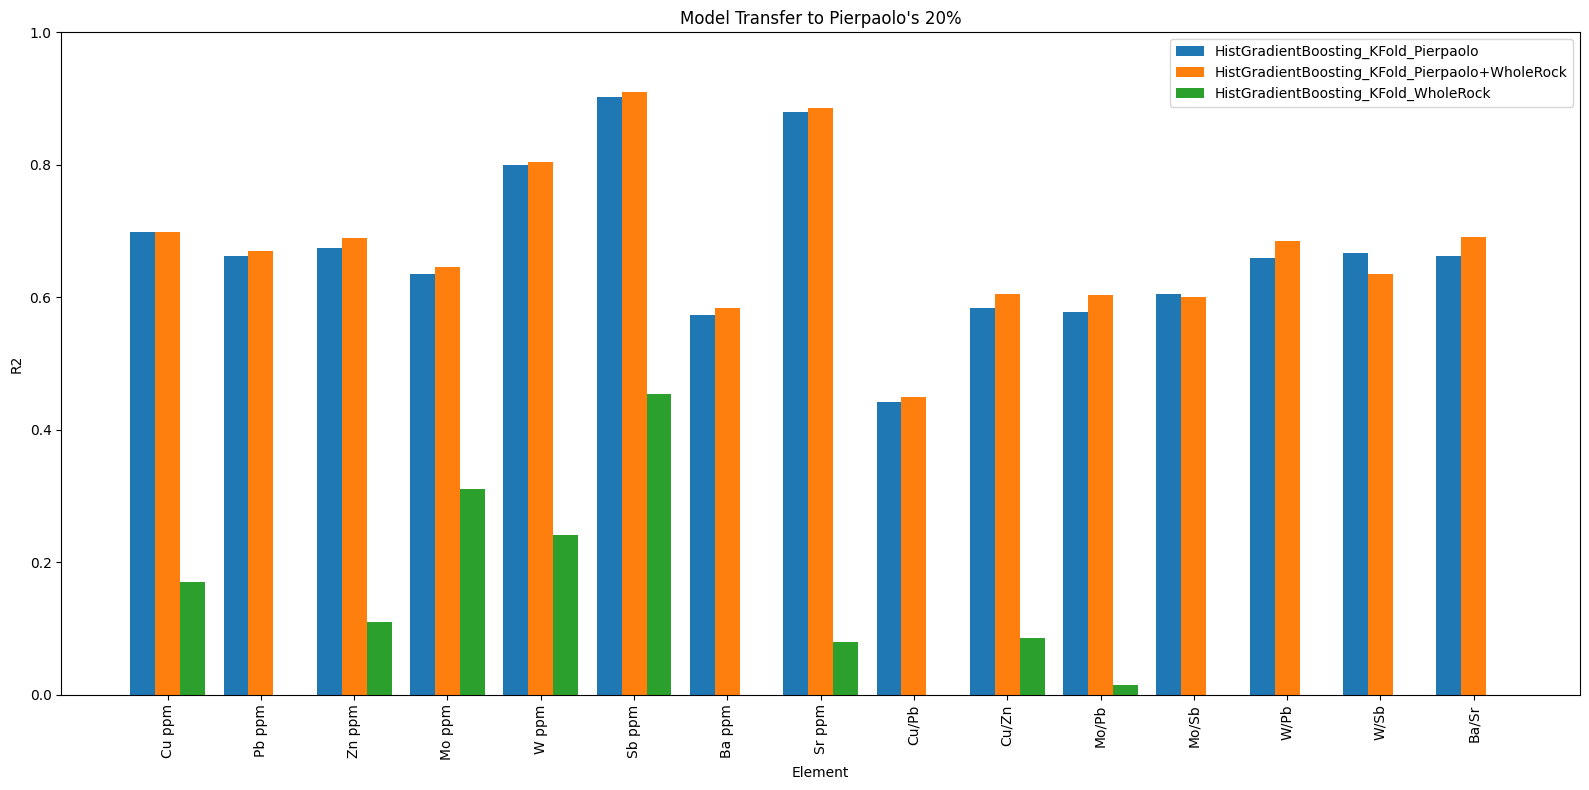

In [21]:
from ModelUtils import CompareVariantsOnGraph

CompareVariantsOnGraph({VARIANT_NAMES[v]: scores for v, scores in results.items()}, TARGETS, title="Model Transfer to Pierpaolo's 20%")